In [2]:
import sys
import numpy as np
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import rankdata, norm
from scipy.spatial.distance import pdist
from scipy.optimize import minimize
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel as C

# ---------------------------------------------------------------------
# Reproducibility setup
# ---------------------------------------------------------------------
SEED = 42                                                 # Random seed

print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()


Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



In [ ]:
X = np.load('..\Function_1_Data\Week_7_Data/F1_Week_7_inputs.npy')
y = np.load('..\Function_1_Data\Week_7_Data/F1_Week_7_outputs.npy')
n, d = X.shape
bounds = np.array([[0.0, 1.0], [0.0, 1.0]])
X.shape, X, y.shape, y

((16, 2),
 array([[0.31940389, 0.76295937],
        [0.57432921, 0.8798981 ],
        [0.73102363, 0.73299988],
        [0.84035342, 0.26473161],
        [0.65011406, 0.68152635],
        [0.41043714, 0.1475543 ],
        [0.31269116, 0.07872278],
        [0.68341817, 0.86105746],
        [0.08250725, 0.40348751],
        [0.88388983, 0.58225397],
        [0.039877  , 0.047989  ],
        [0.482658  , 0.532853  ],
        [0.370965  , 0.537526  ],
        [0.548003  , 0.519056  ],
        [0.168691  , 0.769922  ],
        [0.150125  , 0.19144   ]]),
 (16,),
 array([ 1.32267704e-079,  1.03307824e-046,  7.71087511e-016,
         3.34177101e-124, -3.60606264e-003, -2.15924904e-054,
        -2.08909327e-091,  2.53500115e-040,  3.60677119e-081,
         6.22985647e-048,  5.17204276e-199,  1.16372830e-012,
         2.22966164e-013,  9.50165703e-014, -2.58157098e-130,
         1.64764723e-089]))

In [4]:
# ---------------------------------------------------------------------
# 2. Output transform: rank-based Gaussian copula using the "average" method.
# ---------------------------------------------------------------------
def copula_transform(y):
    n = len(y)
    ranks = rankdata(y, method="average")
    quantiles = (ranks - 0.5) / n
    return norm.ppf(quantiles)

y_train = copula_transform(y)

In [5]:
# ---------------------------------------------------------------------
# 3. Surrogate model: Matern 5/2, ARD, fit with a fixed random_state
# ---------------------------------------------------------------------
def fit_surrogate(X, y_train, seed):
    d = X.shape[1]
    init_length_scales = np.array([np.median(pdist(X[:, [j]])) for j in range(d)])
    length_scale_bounds = (0.02, 2.0)

    kernel = C(1.0, (1e-2, 1e2)) * Matern(
        length_scale=init_length_scales,
        length_scale_bounds=length_scale_bounds,
        nu=2.5,
    )
    gp = GaussianProcessRegressor(
        kernel=kernel,
        alpha=1e-6,
        normalize_y=False,
        n_restarts_optimizer=15,
        random_state=seed,
    )
    gp.fit(X, y_train)
    return gp


gp = fit_surrogate(X, y_train, seed=SEED)

print("=" * 100)
print("FITTED SURROGATE")
print("=" * 100)
print(f"  kernel: {gp.kernel_}")
fitted_ls = gp.kernel_.k2.length_scale
for j in range(d):
    print(f"  length-scale x{j+1} = {fitted_ls[j]:.4f}")
f_best = y_train.max()
print(f"  best observed (copula scale) = {f_best:.4f} at x = {X[np.argmax(y_train)]}")
print()


FITTED SURROGATE
  kernel: 0.895**2 * Matern(length_scale=[0.233, 0.0206], nu=2.5)
  length-scale x1 = 0.2334
  length-scale x2 = 0.0206
  best observed (copula scale) = 1.8627 at x = [0.482658 0.532853]



In [7]:
# ---------------------------------------------------------------------
# 4. Acquisition functions - EI and UCB
# ---------------------------------------------------------------------
def expected_improvement(x, gp, f_best, xi=0.01):
    x = np.atleast_2d(x)
    mu, sigma = gp.predict(x, return_std=True)
    sigma = np.maximum(sigma, 1e-9)
    improvement = mu - f_best - xi
    z = improvement / sigma
    ei = improvement * norm.cdf(z) + sigma * norm.pdf(z)
    ei[sigma < 1e-9] = 0.0
    return ei


def gp_ucb(x, gp, beta=2.0):
    x = np.atleast_2d(x)
    mu, sigma = gp.predict(x, return_std=True)
    return mu + np.sqrt(beta) * sigma

In [8]:
# ---------------------------------------------------------------------
# 5. Acquisition optimizer
# ---------------------------------------------------------------------
def next_point(acq_fn, gp, bounds, rng, n_restarts=25, **acq_kwargs):
    dim = bounds.shape[0]

    def neg_acq(x):
        return -acq_fn(x.reshape(1, -1), gp, **acq_kwargs)[0]

    best_x, best_val = None, np.inf
    starts = rng.uniform(bounds[:, 0], bounds[:, 1], size=(n_restarts, dim))
    for x0 in starts:
        res = minimize(neg_acq, x0=x0, bounds=bounds, method="L-BFGS-B")
        if res.fun < best_val:
            best_val = res.fun
            best_x = res.x
    return best_x, -best_val

rng = np.random.default_rng(SEED)

xi = 0.01
next_x_ei, next_ei_val = next_point(
    expected_improvement, gp, bounds, rng=rng, f_best=f_best, xi=xi
)
print(f"[EI,  xi={xi}]   next query point: {np.round(next_x_ei, 6)}  (EI={next_ei_val:.6f})")

beta = 16.0  # Setting beta large enough in the hope that it will escape the local ridge around the incumbent

next_x_ucb, next_ucb_val = next_point(
    gp_ucb, gp, bounds, rng=rng, beta=beta
)
print(f"[UCB, beta={beta}] next query point: {np.round(next_x_ucb, 6)}  (UCB={next_ucb_val:.6f})")
print()

[EI,  xi=0.01]   next query point: [0.552105 0.538965]  (EI=0.100501)
[UCB, beta=16.0] next query point: [0.663848 0.547838]  (UCB=4.059163)



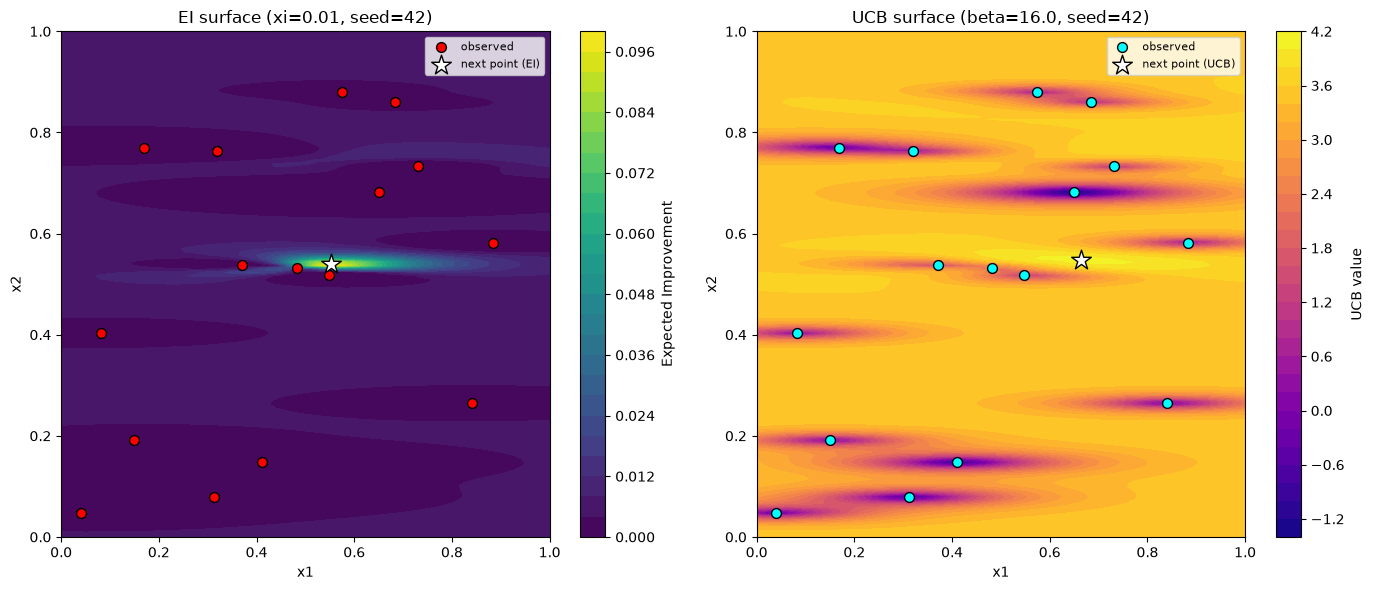

In [9]:
# ---------------------------------------------------------------------
# 6. Plots
# ---------------------------------------------------------------------
grid_n = 150
gx = np.linspace(0, 1, grid_n)
gy = np.linspace(0, 1, grid_n)
GX, GY = np.meshgrid(gx, gy)
grid_points = np.column_stack([GX.ravel(), GY.ravel()])

EI_grid = expected_improvement(grid_points, gp, f_best=f_best, xi=xi).reshape(grid_n, grid_n)
UCB_grid = gp_ucb(grid_points, gp, beta=beta).reshape(grid_n, grid_n)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ax = axes[0]
cf = ax.contourf(GX, GY, EI_grid, levels=30, cmap="viridis")
ax.scatter(X[:, 0], X[:, 1], c="red", edgecolor="k", s=50, label="observed")
ax.scatter(*next_x_ei, c="white", edgecolor="black", s=220, marker="*", label="next point (EI)")
plt.colorbar(cf, ax=ax, label="Expected Improvement")
ax.set_title(f"EI surface (xi={xi}, seed={SEED})")
ax.set_xlabel("x1"); ax.set_ylabel("x2")
ax.legend(loc="upper right", fontsize=8)

ax = axes[1]
cf2 = ax.contourf(GX, GY, UCB_grid, levels=30, cmap="plasma")
ax.scatter(X[:, 0], X[:, 1], c="cyan", edgecolor="k", s=50, label="observed")
ax.scatter(*next_x_ucb, c="white", edgecolor="black", s=220, marker="*", label="next point (UCB)")
plt.colorbar(cf2, ax=ax, label="UCB value")
ax.set_title(f"UCB surface (beta={beta}, seed={SEED})")
ax.set_xlabel("x1"); ax.set_ylabel("x2")
ax.legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()